<a href="https://colab.research.google.com/github/mrbedoya/ml-2026/blob/main/01_Preparaci%C3%B3nDataset02Clasificacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preparación del dataset de créditos bancarios

## 1. Librerias y configuraciones previas


In [1]:
# Tratamiento de datos
# ==============================================================================
import pandas as pd
import numpy as np

# Preparación de datos
# ==============================================================================
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import MinMaxScaler

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Interactuar con el sistema operativo y solicitudes HTTP
# ==============================================================================
import os
import sys
import requests
from urllib.parse import urljoin

# Configuración warnings
# ==============================================================================
import warnings
# Se ocultan solo los avisos informativos de versiones; los demás avisos siguen visibles
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [2]:
# Parametros globales
# ==============================================================================

# URL base de GitHub para el repositorio
GITHUB_BASE_URL = 'https://raw.githubusercontent.com/mrbedoya/ml-2026/main/'

# Nombres de los archivos requeridos
DATASET_FILE_NAME = '02_GermanCredit.csv'
UTILS_FILE_NAME = 'funciones.py'

# Nombres de los directorios para utilidades y datasets
DATASETS_PATH = 'datasets/'
UTILS_PATH = 'utils/'

# URL completa del dataset y utils en GitHub (urljoin evita errores con las barras)
github_dataset_url = urljoin(GITHUB_BASE_URL, DATASETS_PATH + DATASET_FILE_NAME)
github_utils_url = urljoin(GITHUB_BASE_URL, UTILS_PATH + UTILS_FILE_NAME)

# Rutas locales completas de datasets y utils
local_dataset_path = os.path.join(DATASETS_PATH, DATASET_FILE_NAME)
local_utils_path = os.path.join(UTILS_PATH, UTILS_FILE_NAME)

### (Opcional) Cargar datos desde Google Drive

La celda siguiente muestra una **alternativa** para trabajar con archivos guardados en Google Drive, en vez de descargarlos desde GitHub. Se deja comentada porque en este notebook usamos la descarga directa desde el repositorio (más fácil de reproducir para cualquier estudiante), pero queda como referencia por si prefieres montar tu propio Drive.

In [3]:
## Cargar datos desde Google Drive
## ==============================================================================

#from google.colab import drive

## Montar Google Drive
#drive.mount('/gdrive')

## Establece el directorio de trabajo dentro de directorio especificado en Google Drive
#os.chdir("/gdrive/MyDrive/01_Academia/02_Cursos/20260401_ApredinzajeAutomáticoI_UdeA/")

## Listar archivos de directorio
##!ls

In [4]:
# Funcion local para la carga de archivos
# ==============================================================================

def download_file(url, path, description, force=False, timeout=30):
    '''
    Descarga un archivo desde una URL y lo guarda localmente en un path.
    Si el archivo ya existe no se vuelve a descargar (usar force=True para obligarlo).

    Args:
        url (str): URL del archivo
        path (str): Ruta local de destino
        description (str): Descripción del archivo
        force (bool): Si es True, descarga aunque el archivo ya exista
        timeout (int): Segundos máximos de espera de la descarga
    Returns:
        None
    '''
    if os.path.exists(path) and not force:
        print(f"{description} ya existe en: {path} (no se vuelve a descargar)")
        return

    print(f"Descargando {description} desde: {url}")

    # Realiza una solicitud HTTP GET a la URL proporcionada
    response = requests.get(url, timeout=timeout)

    # Lanza una excepción si la descarga falla (código de estado HTTP no 200)
    response.raise_for_status()

    # Abre el archivo local en modo de escritura binaria ('wb')
    with open(path, 'wb') as f:
        # Escribe el contenido binario de la respuesta HTTP en el archivo local
        f.write(response.content)

    # Imprime un mensaje confirmando que la descarga fue exitosa y la ruta de guardado
    print(f"{description} descargado exitosamente a: {path}")

In [5]:
## Configuración entorno Colab
# ==============================================================================

# Creación de directorios locales
os.makedirs(DATASETS_PATH, exist_ok=True)
os.makedirs(UTILS_PATH, exist_ok=True)

# Descarga de archivos
download_file(github_dataset_url, local_dataset_path, "dataset")
download_file(github_utils_url, local_utils_path, "funciones")

Descargando dataset desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/datasets/02_GermanCredit.csv
dataset descargado exitosamente a: datasets/02_GermanCredit.csv
Descargando funciones desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/utils/funciones.py
funciones descargado exitosamente a: utils/funciones.py


## 2. Funciones

En esta sección importamos las funciones reutilizables de `funciones.py` (descargado arriba). Aquí usaremos `multiple_plot` para graficar; en los notebooks posteriores se usan además otras utilidades (curva ROC, VIF, matriz de correlación, etc.).

In [6]:
# Funciones externas
# ==============================================================================

# Añade la ruta definida en 'UTILS_PATH' al 'sys.path' para que Python pueda encontrar módulos
sys.path.append(UTILS_PATH)

# Importa funciones externas
from funciones import multiple_plot

## 3. Carga del dataset

Este dataset extraído de *UCI* (nombrado: **german.data** ) contiene información sobre **aprobación de créditos bancarios**, los cuales serán usados para la predicción de un proceso de clasificación indicando si el cliente es bueno o malo, a partir de las diferentes variables.

A continuación una breve descripción de las variables:

****


| Columna                     | Descripción                                                   | Ejemplo |
|:-----------------------------|:---------------------------------------------------------------|:---------|
| checking_account_status     | Estado de la cuenta corriente del solicitante                 | < 0 DM     |
| loan_duration_mo            | Duración del préstamo en meses                                | 42      |
| credit_history              | Historial crediticio del solicitante                          | current loans paid     |
| purpose                     | Propósito del préstamo                                         | furniture/equipment     |
| loan_amount                 | Monto del préstamo en unidades monetarias                      | 7882    |
| savings_account_balance     | Saldo de la cuenta de ahorros del solicitante                  | < 100 DM     |
| time_employed_yrs           | Tiempo de empleo en años                                       | 4 - 7 years       |
| payment_pcnt_income         | Porcentaje del ingreso que se destina al pago del préstamo     | 2       |
| gender_status               | Estado civil y género del solicitante                          | male-single     |
| other_signators             | Indicador de si hay otros firmantes en el préstamo             | guarantor    |
| time_in_residence           | Tiempo de residencia en años                                   | 4       |
| property                    | Tipo de propiedad                                              | building society savings/life insurance    |
| age_yrs                     | Edad en años                                                  | 45      |
| other_credit_outstanding    | Indicador de si hay otros créditos en curso                     | none    |
| home_ownership              | Indicador de si el solicitante es dueño o inquilino de su hogar | for free|
| number_loans                | Número de préstamos existentes en el momento de la solicitud    | 1       |
| job_category                | Categoría laboral del solicitante                              | unskilled-resident    |
| dependents                  | Número de personas que dependen del solicitante                 | 2       |
| telephone                   | Indicador de si el solicitante tiene un teléfono                 | yes    |
| foreign_worker              | Indicador de si el solicitante es trabajador extranjero         | yes    |
| bad_credit                  | Indicador de si el préstamo resultó en un incumplimiento        | 0       |


****

> **Nota ética:** este dataset incluye variables sensibles (por ejemplo `gender_status`, `age_yrs` y `foreign_worker`). En un caso real, usarlas para decidir sobre créditos puede generar discriminación y está regulado; aquí se conservan solo con fines didácticos.

Url origen datos: https://archive.ics.uci.edu/ml/datasets/statlog+(german+credit+data)

In [7]:
#Cargar el dataset
d = pd.read_csv(local_dataset_path)

In [8]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Customer ID               1000 non-null   int64 
 1   checking_account_status   1000 non-null   object
 2   loan_duration_mo          1000 non-null   int64 
 3   credit_history            1000 non-null   object
 4   purpose                   1000 non-null   object
 5   loan_amount               1000 non-null   int64 
 6   savings_account_balance   1000 non-null   object
 7   time_employed_yrs         1000 non-null   object
 8   payment_pcnt_income       1000 non-null   int64 
 9   gender_status             1000 non-null   object
 10  other_signators           1000 non-null   object
 11  time_in_residence         1000 non-null   int64 
 12  property                  1000 non-null   object
 13  age_yrs                   1000 non-null   int64 
 14  other_credit_outstanding 

In [9]:
d.head(2)

,Customer ID,checking_account_status,loan_duration_mo,credit_history,purpose,loan_amount,savings_account_balance,time_employed_yrs,payment_pcnt_income,gender_status,...,property,age_yrs,other_credit_outstanding,home_ownership,number_loans,job_category,dependents,telephone,foreign_worker,bad_credit
0,1122334,< 0 DM,6,critical account - other non-bank loans,radio/television,1169,unknown/none,>= 7 years,4,male-single,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,6156361,0 - 200 DM,48,current loans paid,radio/television,5951,< 100 DM,1 - 4 years,2,female-divorced/separated/married,...,real estate,22,none,own,1,skilled,1,none,yes,1


## 4. Limpieza de datos (Data Cleaning)

In [10]:
#Borrando columnas innecesarias: 'Customer ID' es solo un identificador y no aporta información para predecir
d.drop(['Customer ID'], axis='columns', inplace=True)

In [11]:
#Verificación y eliminación de registros duplicados

#Verificación de registros duplicados
d.loc[d.duplicated()]

,checking_account_status,loan_duration_mo,credit_history,purpose,loan_amount,savings_account_balance,time_employed_yrs,payment_pcnt_income,gender_status,other_signators,...,property,age_yrs,other_credit_outstanding,home_ownership,number_loans,job_category,dependents,telephone,foreign_worker,bad_credit


In [12]:
# eliminación de registros duplicados
d = d.drop_duplicates()

#Reiniciar el indice
d.reset_index(drop=True, inplace=True)

## 5. Separación de datos de entrenamiento y prueba

Para evitar fuga de información (*data leakage*), separamos aquí el conjunto de entrenamiento y de prueba, **antes** de explorar los datos y de calcular cualquier estadística que se use para transformarlos (agrupación de categorías, valores atípicos, sobremuestreo).

De aquí en adelante:
- `d` se refiere **únicamente al conjunto de entrenamiento**. Todo el análisis exploratorio y la preparación de datos que siguen (secciones 6 y 7) se hacen solo con estos datos.
- `d_test` es el conjunto de prueba: se aparta intacto y solo se le aplica la misma agrupación de categorías de `purpose`. Nunca se le eliminan atípicos, se rebalancea ni se ajusta nada con él: en un escenario real no podemos "limpiar" ni rebalancear los datos que llegan para predicción.

In [13]:
# Se separa el conjunto de datos en entrenamiento (90%) y prueba (10%) ANTES de explorar y transformar los datos.
# stratify=bad_credit mantiene la misma proporción de buenos y malos créditos en entrenamiento y prueba

d, d_test = train_test_split(
                d,
                train_size   = 0.90,
                random_state = 1234,
                shuffle      = True,
                stratify     = d['bad_credit']
            )

d.reset_index(drop=True, inplace=True)
d_test.reset_index(drop=True, inplace=True)

print(f"Filas de entrenamiento: {d.shape[0]}")
print(f"Filas de prueba: {d_test.shape[0]}")

Filas de entrenamiento: 900
Filas de prueba: 100


## 6. Visualización de datos

### Variables de entrada

In [14]:
#Lista de variables categóricas
catCols = d.select_dtypes(include = ["object", 'category']).columns.tolist()

d[catCols].head(2)

,checking_account_status,credit_history,purpose,savings_account_balance,time_employed_yrs,gender_status,other_signators,property,other_credit_outstanding,home_ownership,job_category,telephone,foreign_worker
0,> 200 DM or salary assignment,critical account - other non-bank loans,car (used),500 - 1000 DM,1 - 4 years,male-single,none,car or other,none,own,skilled,yes,yes
1,0 - 200 DM,current loans paid,car (used),unknown/none,unemployed,male-divorced/separated,none,real estate,none,own,highly skilled,yes,yes


In [15]:
#Lista de variables numéricas

numCols=d.select_dtypes(include = ['float64','int32','int64']).columns.tolist()

#Se elimina el elemento bad_credit de la lista de variables numéricas
numCols.remove('bad_credit')

d[numCols].head(2)

,loan_duration_mo,loan_amount,payment_pcnt_income,time_in_residence,age_yrs,number_loans,dependents
0,15,2360,2,2,36,1,1
1,20,6468,1,4,60,1,1


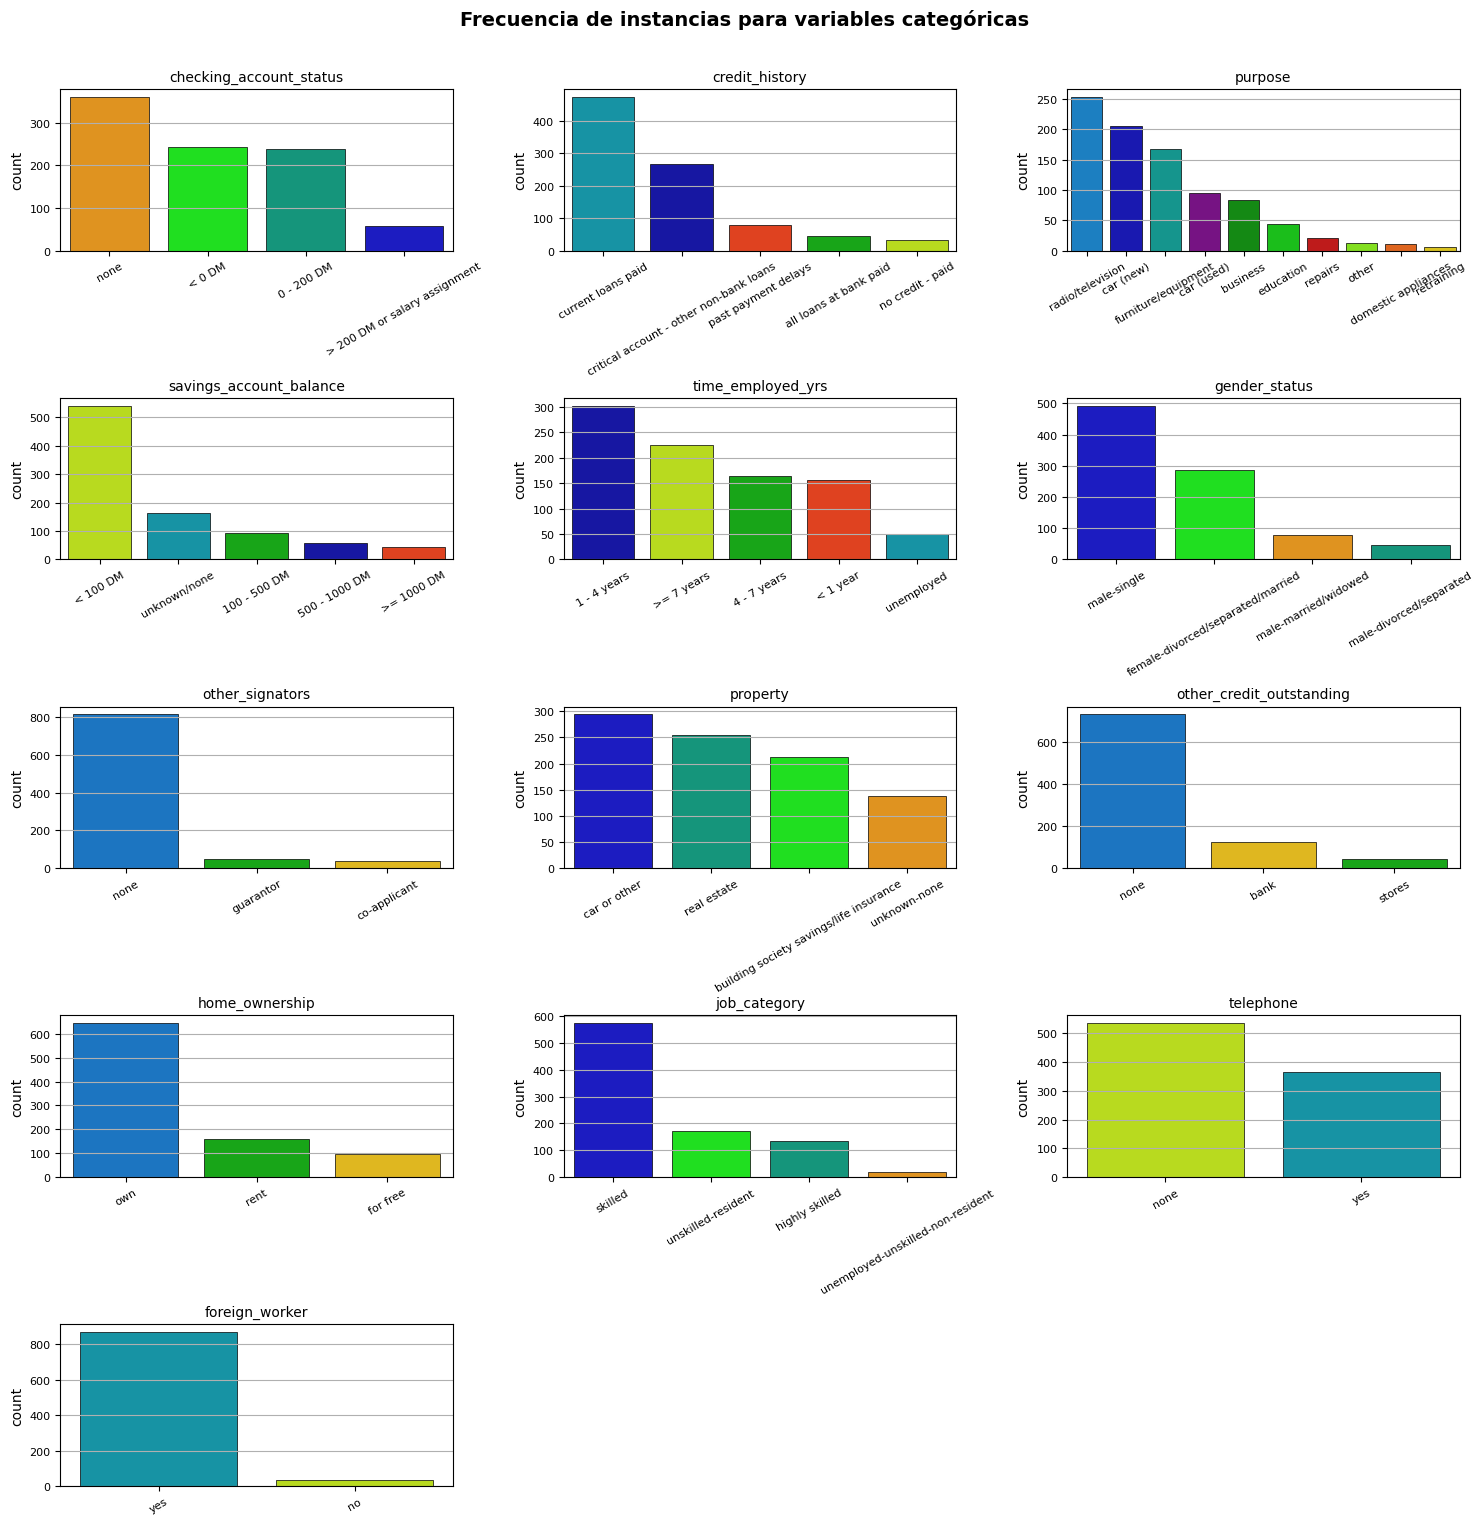

In [16]:
#Visualización de frecuencia de instancias para variables categóricas
multiple_plot(3, d , catCols, None, 'countplot', 'Frecuencia de instancias para variables categóricas',30)

In [17]:
# Distribución de cada variable categórica en el conjunto de datos

for col in catCols:
    print("="*5 + f" {col} " + "="*20)
    print(d[col].value_counts())
    print()

===== checking_account_status ====================
checking_account_status
none                             361
< 0 DM                           244
0 - 200 DM                       238
> 200 DM or salary assignment     57
Name: count, dtype: int64

===== credit_history ====================
credit_history
current loans paid                         475
critical account - other non-bank loans    267
past payment delays                         80
all loans at bank paid                      45
no credit - paid                            33
Name: count, dtype: int64

===== purpose ====================
purpose
radio/television       254
car (new)              205
furniture/equipment    168
car (used)              95
business                84
education               44
repairs                 21
other                   12
domestic appliances     11
retraining               6
Name: count, dtype: int64

===== savings_account_balance ====================
savings_account_balance
< 100 DM        

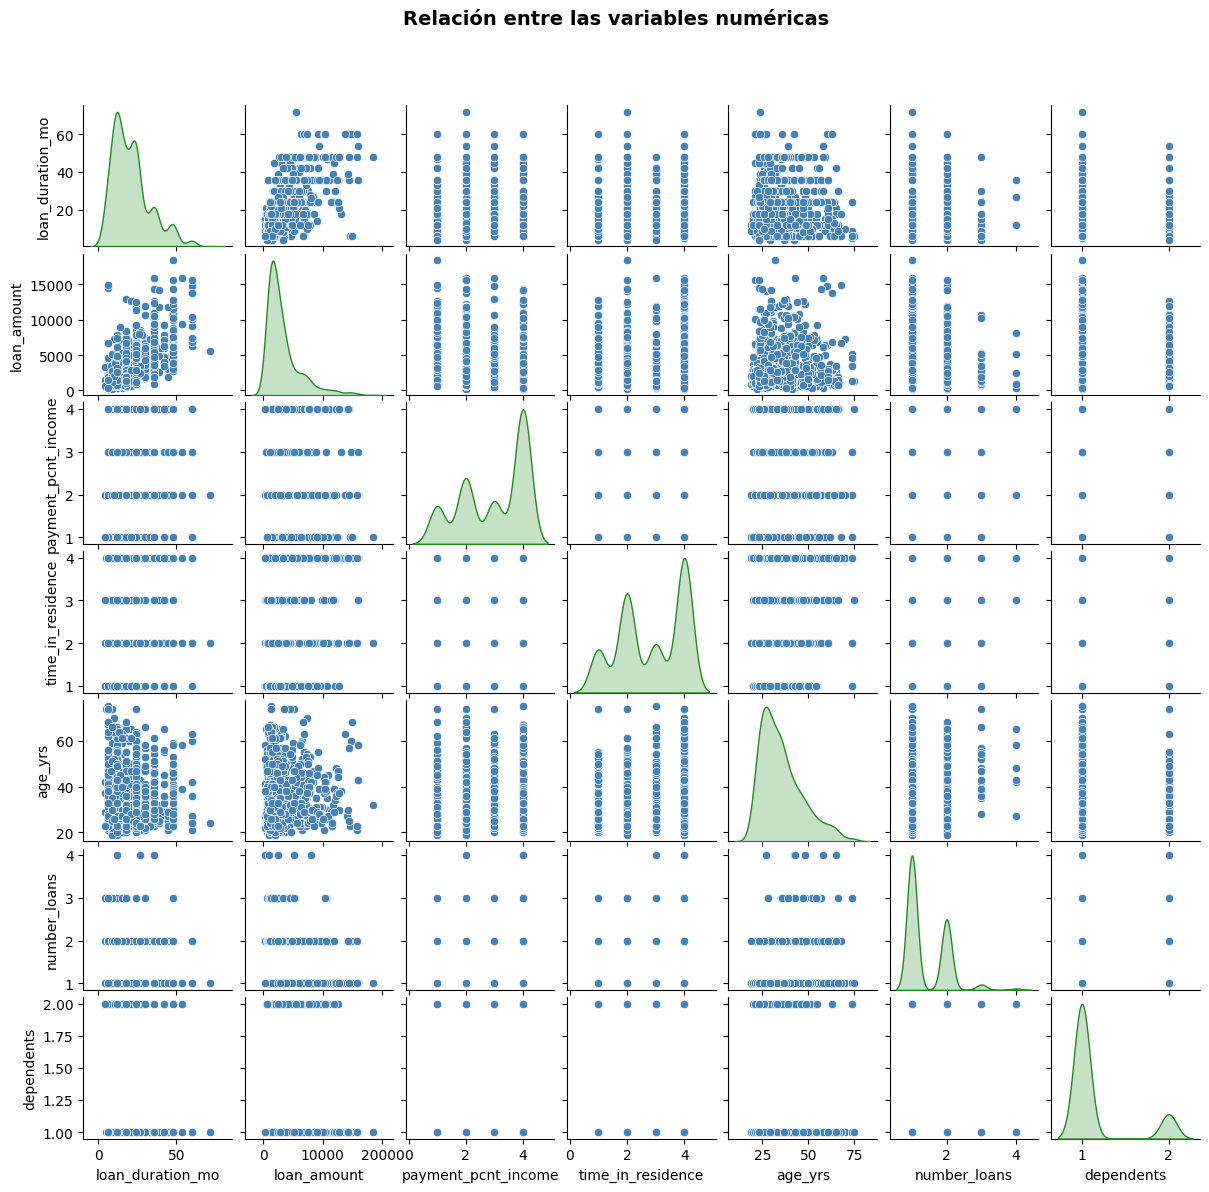

In [18]:
#Visualización de variables numéricas
multiple_plot(1, d , numCols, None, 'scatterplot', 'Relación entre las variables numéricas',30)

### Variable de salida

In [19]:
d.groupby('bad_credit').bad_credit.count().sort_values(ascending=False)

,bad_credit
bad_credit,
0,630
1,270


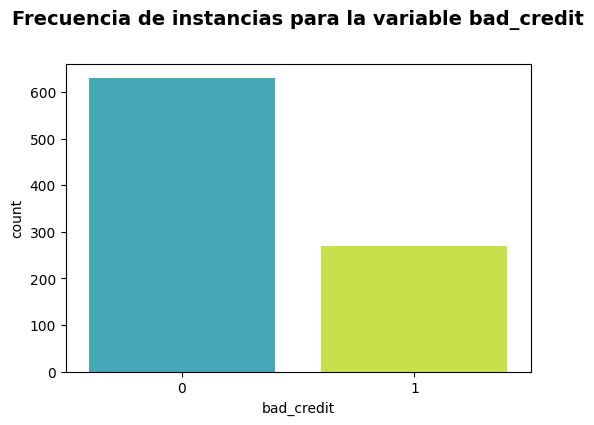

In [20]:
multiple_plot(1, d , None, 'bad_credit', 'countplot', 'Frecuencia de instancias para la variable bad_credit',0)

## 7. Preparación de datos

### Imputaciones

No se requieren imputaciones, solo se realizará la verificación de la completitud

In [21]:
# Identificación de valores nulos para las variables numéricas
for col in d[numCols]:
    print (col, np.sum(pd.isnull(d[col])))

loan_duration_mo 0
loan_amount 0
payment_pcnt_income 0
time_in_residence 0
age_yrs 0
number_loans 0
dependents 0


In [22]:
# Identificación de valores nulos para las variables categóricas
for col in d[catCols]:
    print (col, np.sum(pd.isnull(d[col])))

checking_account_status 0
credit_history 0
purpose 0
savings_account_balance 0
time_employed_yrs 0
gender_status 0
other_signators 0
property 0
other_credit_outstanding 0
home_ownership 0
job_category 0
telephone 0
foreign_worker 0


### Transformaciones

In [23]:
#Eliminación de categorías pequeñas para la variable purpose

d['purpose'].value_counts().sort_values(ascending=False)

,count
purpose,
radio/television,254
car (new),205
furniture/equipment,168
car (used),95
business,84
education,44
repairs,21
other,12
domestic appliances,11


In [24]:
#Reemplazo de valores para la agrupación de categorías

#Diccionario con los reemplazos a realizar
reemplazos = {  "car (new)": "car"
              , "car (used)": "car"
              , "retraining": "education"
              , "domestic appliances": "repairs"}


#Se reemplazan los valores de acuerdo con el diccionario creado anteriormente
d['purpose'] = d['purpose'].map(reemplazos).fillna(d['purpose'])


#Visualización de las nuevos valores agrupados para la categoria 'purpose'
d['purpose'].value_counts().sort_values(ascending=False)

,count
purpose,
car,300
radio/television,254
furniture/equipment,168
business,84
education,50
repairs,32
other,12


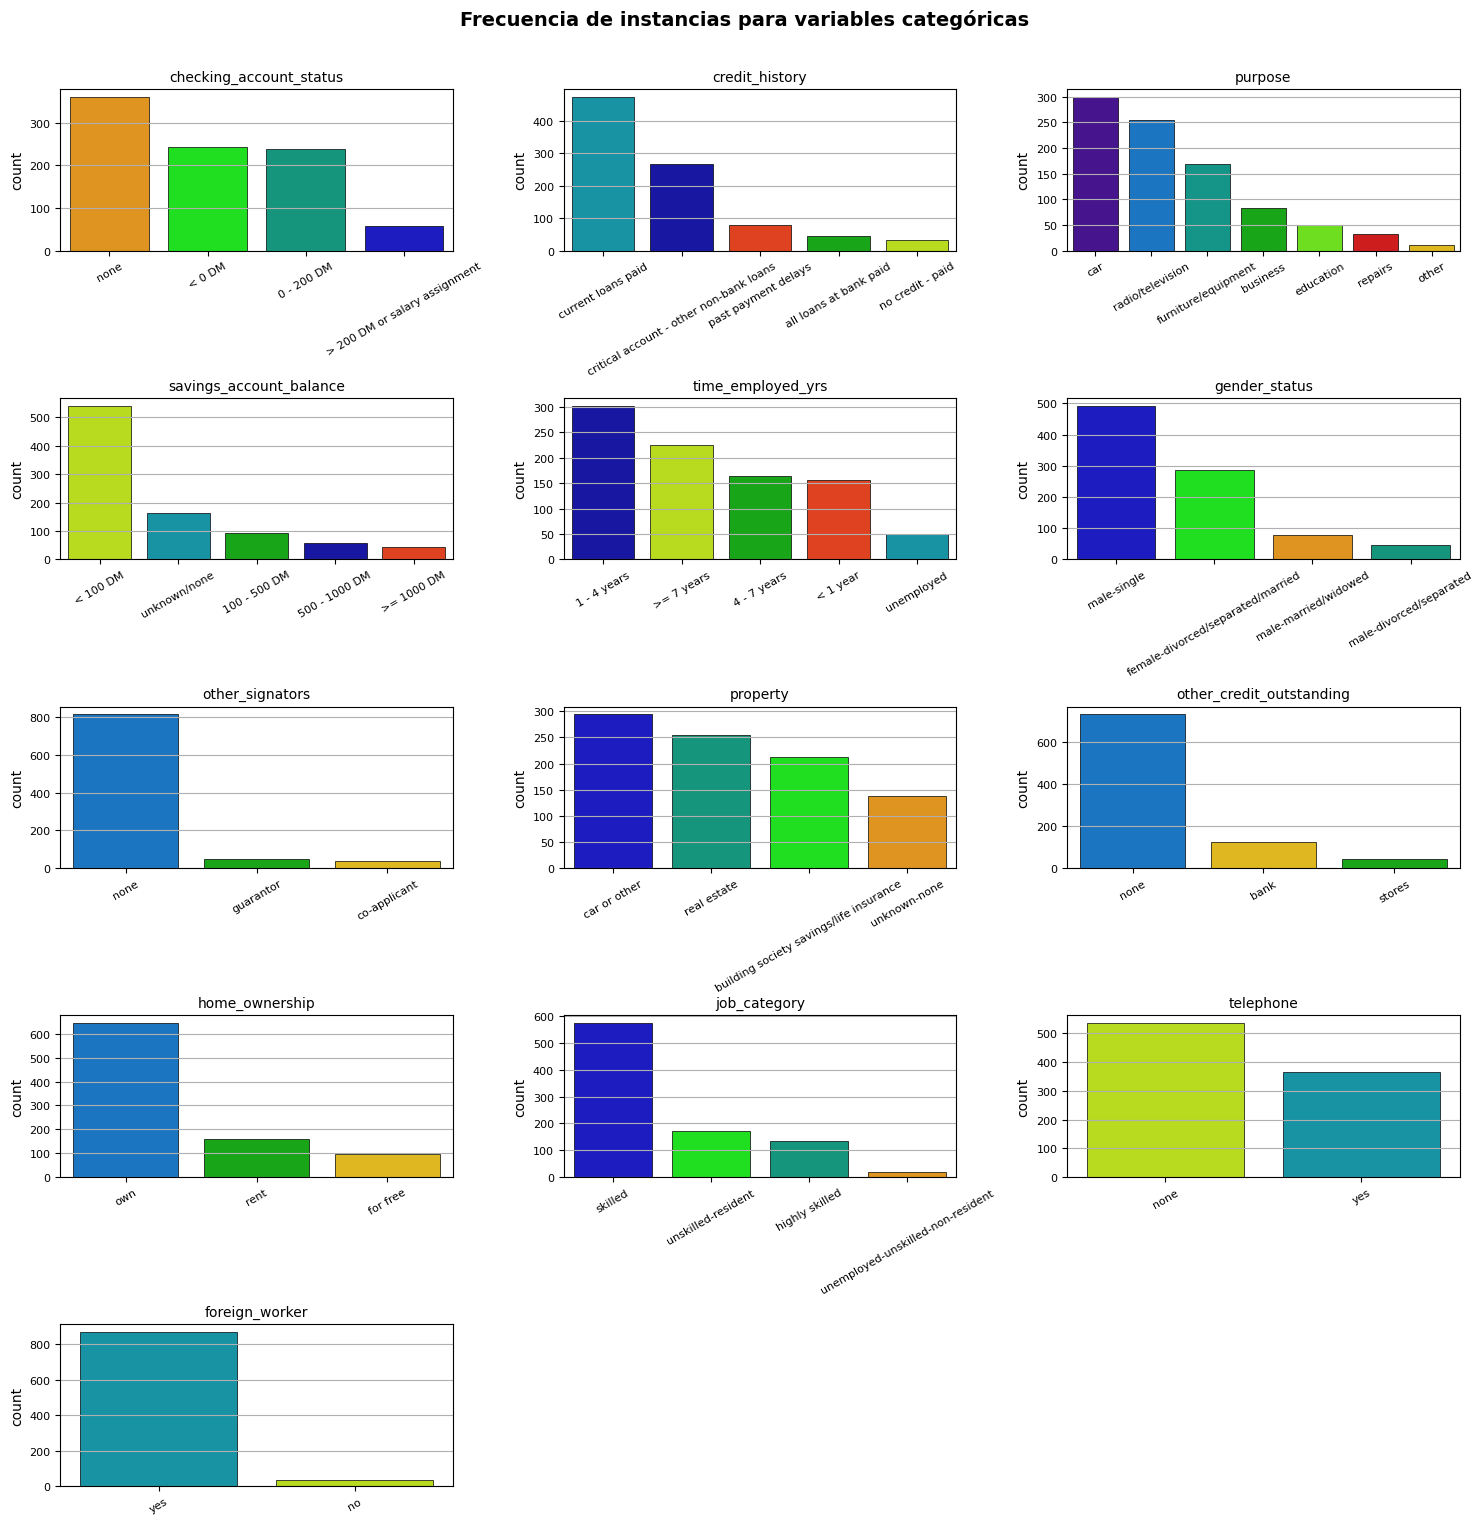

In [25]:
#Visualización de frecuencia de instancias para variables categóricas
multiple_plot(3, d , catCols, None, 'countplot', 'Frecuencia de instancias para variables categóricas',30)

In [26]:
# Se aplica al conjunto de prueba la MISMA agrupación de categorías definida sobre el entrenamiento
d_test['purpose'] = d_test['purpose'].map(reemplazos).fillna(d_test['purpose'])

### Valores atípicos para las variables de entrada

In [27]:
#utilización de LocalOutlierFactor con 13 vecinos para identificar valores atípicos en las variables de entrada
#n_neighbors=13: numero de vecinos considerados para evaluar la densidad local de cada punto.
#contamination=0.1: se asume que aproximadamente un 10% de los registros son atípicos;
#                    es una estimación inicial y puede ajustarse según el conocimiento del dominio.

# LOF se basa en distancias: se escalan las variables (MinMaxScaler) únicamente para calcular las distancias,
# de modo que 'loan_amount' (del orden de miles) no domine a variables como 'age_yrs' o 'dependents'.
X_lof = MinMaxScaler().fit_transform(d[numCols])

# crear un objeto LocalOutlierFactor con n_neighbors=13
lof = LocalOutlierFactor(n_neighbors=13, contamination=0.1)

# identificar los valores atípicos por medio de lof (solo sobre el conjunto de entrenamiento 'd')
y_pred = lof.fit_predict(X_lof)

# Identificar los índices de los valores atípicos
outliers = y_pred == -1

print('Indices de valores atípicos: ', d[outliers].index.tolist())

Indices de valores atípicos:  [7, 13, 20, 21, 49, 57, 59, 108, 136, 170, 172, 212, 215, 232, 236, 238, 252, 254, 262, 263, 264, 279, 280, 282, 283, 300, 314, 323, 325, 349, 352, 353, 366, 368, 375, 378, 402, 409, 422, 432, 469, 492, 502, 513, 516, 520, 528, 536, 550, 561, 562, 572, 574, 589, 595, 599, 602, 608, 611, 626, 649, 669, 682, 686, 700, 720, 722, 741, 755, 756, 761, 765, 766, 799, 805, 811, 813, 814, 823, 824, 832, 841, 855, 859, 864, 868, 873, 880, 892, 898]


In [28]:
# Eliminar los valores atípicos del dataframe original (solo del conjunto de entrenamiento)
d = d.loc[~outliers].reset_index(drop=True)

In [29]:
d.shape

(810, 21)

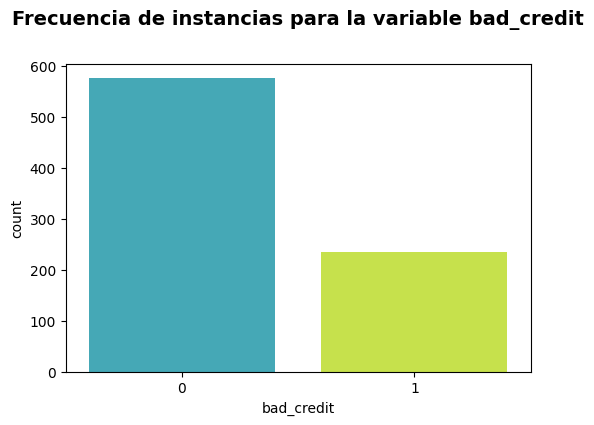

In [30]:
multiple_plot(1, d , None, 'bad_credit', 'countplot', 'Frecuencia de instancias para la variable bad_credit',0)

In [31]:
d.groupby('bad_credit').bad_credit.count().sort_values(ascending=False)

,bad_credit
bad_credit,
0,576
1,234


### Sobremuestreo (oversampling)

Este paso y el anterior (eliminación de atípicos) se aplican **únicamente sobre `d` (el conjunto de entrenamiento)**. El conjunto de prueba `d_test` se deja intacto: en un escenario real no podemos "limpiar" ni rebalancear los datos que llegan para predicción, así que el conjunto de prueba debe reflejar la distribución real de los datos.

> **Advertencia:** el sobremuestreo aleatorio **duplica** filas de la clase minoritaria (`bad_credit = 1`), por lo que el archivo exportado `02_GermanCredit_Prep.csv` contiene copias de las mismas filas. Si ese archivo se usa después con validación cruzada, una copia puede quedar en el pliegue de entrenamiento y otra en el de validación, y las métricas saldrían infladas. En los notebooks que usan validación cruzada esto se maneja sobremuestreando *dentro* de cada pliegue (por ejemplo con `imblearn.pipeline.Pipeline`) o usando `class_weight='balanced'`.

In [32]:
# Se crea un objeto RandomOverSampler que permite crear copias aleatorias de las muestras de la clase
# minoritaria para igualar el número de muestras entre las diferentes clases.
oversampler = RandomOverSampler(random_state=1234)

# Se realiza el sobremuestreo para las variables de entrada y salida (fit_resample ya devuelve un DataFrame y una Serie)
X_resampled, y_resampled = oversampler.fit_resample(d.drop('bad_credit', axis=1), d['bad_credit'])

# Se concatenan horizontalmente las variables de entrada y la variable de salida balanceadas
d = pd.concat([X_resampled, y_resampled], axis=1)

In [33]:
d.shape

(1152, 21)

In [34]:
# Dataset balanceado
d.head(2)

,checking_account_status,loan_duration_mo,credit_history,purpose,loan_amount,savings_account_balance,time_employed_yrs,payment_pcnt_income,gender_status,other_signators,...,property,age_yrs,other_credit_outstanding,home_ownership,number_loans,job_category,dependents,telephone,foreign_worker,bad_credit
0,> 200 DM or salary assignment,15,critical account - other non-bank loans,car,2360,500 - 1000 DM,1 - 4 years,2,male-single,none,...,car or other,36,none,own,1,skilled,1,yes,yes,0
1,0 - 200 DM,20,current loans paid,car,6468,unknown/none,unemployed,1,male-divorced/separated,none,...,real estate,60,none,own,1,highly skilled,1,yes,yes,0


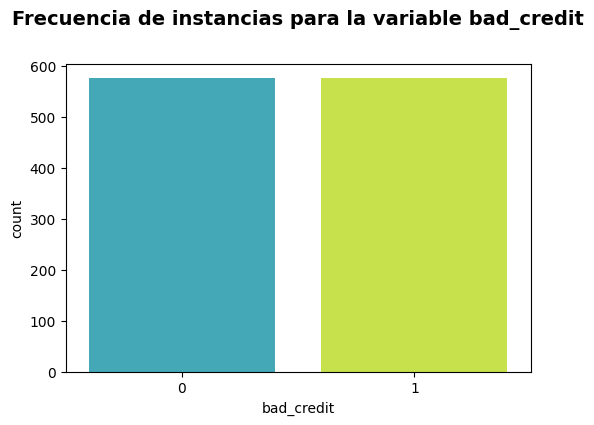

In [35]:
multiple_plot(1, d , None, 'bad_credit', 'countplot', 'Frecuencia de instancias para la variable bad_credit',0)

In [36]:
# Se dejan los nombres 'df' (entrenamiento) y 'dp' (prueba) para mantener consistencia con la sección de exportación
df = d
dp = d_test[df.columns]  # se asegura el mismo orden de columnas que en entrenamiento

print(f"Filas de entrenamiento (df): {df.shape[0]}")
print(f"Filas de prueba (dp): {dp.shape[0]}")

Filas de entrenamiento (df): 1152
Filas de prueba (dp): 100


## 8. Exportar el dataset

Se exportan `df` (entrenamiento, preparado y balanceado) y `dp` (prueba, sin eliminar atípicos ni rebalancear; solo con la misma agrupación de `purpose` aplicada al entrenamiento).

> **Nota:** en Google Colab los archivos exportados se guardan en el disco temporal de la sesión y se pierden al cerrarla. Si quieres conservarlos, descárgalos y súbelos al repositorio (carpeta `datasets/`), ya que los notebooks siguientes los descargan desde GitHub.

In [37]:
# Exportamos los dataframes a archivos CSV
df.to_csv(os.path.join(DATASETS_PATH, '02_GermanCredit_Prep.csv'), index=False)
dp.to_csv(os.path.join(DATASETS_PATH, '02_GermanCredit_Prue.csv'), index=False)

print(f"Entrenamiento exportado: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Prueba exportado: {dp.shape[0]} filas x {dp.shape[1]} columnas")

Entrenamiento exportado: 1152 filas x 21 columnas
Prueba exportado: 100 filas x 21 columnas


### Referencias


- *Dataset:*  
    - https://archive.ics.uci.edu/ml/datasets/statlog+(german+credit+data)
    
    
- *Machine learning con Python y Scikit-learn:*
    - https://www.cienciadedatos.net/documentos/py06_machine_learning_python_scikitlearn.html
    
    
- *LocalOutlierFactor:*
    - https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html
    

- *imbalanced-learn (RandomOverSampler):*
    - https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.RandomOverSampler.html


- *scikit-learn:*    
    - https://scikit-learn.org/stable/
    - https://scikit-learn.org/stable/user_guide.html
  
  
- *Gráficas con  seaborn:*
    - https://ichi.pro/es/como-utilizar-python-seaborn-para-analisis-de-datos-exploratorios-28897898172180

  